# 07. Random Forest Regressor

**Project** · Agriculture Crop Yield Prediction  
**Problem type** · Regression

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

A regression forest combines the numeric predictions of many decision trees. It can learn that yield responds to rainfall differently under low and high irrigation. Averaging helps stabilize estimates when individual trees learn different cutoffs.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

Rainfall plus four times irrigation hours acts as a water index. Yield peaks near a water index of 745, 25 °C and pH 6.5. Fertilizer has diminishing returns, extra irrigation has a small hot-weather effect, and Gaussian noise with standard deviation 0.46 t/ha is added before flooring.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `rainfall_mm` | decimal | mm | Growing-season rainfall |
| `temperature_c` | decimal | °C | Average growing-season temperature |
| `soil_ph` | decimal | pH | Soil acidity |
| `fertilizer_kg_ha` | decimal | kg/ha | Fertilizer applied per hectare |
| `irrigation_hours` | decimal | hours | Seasonal operating hours of irrigation |
| `crop_yield_t_ha` | decimal | t/ha | Observed continuous outcome |

**Independent variables (X)** · `rainfall_mm`, `temperature_c`, `soil_ph`, `fertilizer_kg_ha`, `irrigation_hours`.

**Dependent variable (y)** · `crop_yield_t_ha` is the continuous quantity to predict in t/ha. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "07_crop_yield.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 6)


,rainfall_mm,temperature_c,soil_ph,fertilizer_kg_ha,irrigation_hours,crop_yield_t_ha
0,751.7,15.5,7.83,138.5,35.2,5.50
1,577.6,26.1,7.54,130.5,67.8,7.04
2,651.8,32.0,4.97,131.4,65.3,5.67
3,921.7,30.1,7.88,72.9,27.6,5.46
4,848.0,21.4,7.34,148.6,36.3,7.40
5,903.1,33.7,5.46,45.5,45.2,4.48
6,1036.7,19.1,5.23,178.6,68.5,4.18
7,812.2,18.6,7.76,189.7,46.5,5.59
8,234.1,16.1,7.28,26.0,65.9,4.35
9,569.3,25.3,6.22,119.7,19.0,8.13


rainfall_mm         float64
temperature_c       float64
soil_ph             float64
fertilizer_kg_ha    float64
irrigation_hours    float64
crop_yield_t_ha     float64
dtype: object

## 3. Mathematical Understanding

The forest predicts $\hat y(x)=B^{-1}\sum_{b=1}^B T_b(x)$, where $x$ is a field profile, $B$ is the tree count and $T_b(x)$ is tree $b$’s leaf prediction. In each squared-error tree that prediction is the mean yield of training rows in its leaf, including repeated bootstrap rows.

If three trees estimate $5.0$, $5.8$ and $6.3$ t/ha, the forest predicts $(5.0+5.8+6.3)/3=5.7$ t/ha. For equally variable trees with variance $\sigma^2$ and pairwise correlation $\rho$, averaging gives variance $\sigma^2[\rho+(1-\rho)/B]$, illustrating why diversity matters.

[scikit-learn user guide](https://scikit-learn.org/stable/modules/ensemble.html#forest)

## 4. Working Principle

Sample training fields with replacement, grow regression trees with randomized candidate features, then route a new field through every tree. Average the leaf means. Different tree structures smooth the jumps of an individual tree, while the ensemble remains a collection of piecewise constants.

| Contributor | Yield estimate |
| --- | --- |
| Tree A | 5.0 t/ha |
| Tree B | 5.8 t/ha |
| Tree C | 6.3 t/ha |
| Average | 5.7 t/ha |

**Workflow diagram**

`Raw input` → `Imputed numeric values and any category indicators` → `Averages numeric predictions from randomized trees` → `Estimate in t/ha`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows the range and shape of the outcome. Feature plots show variation. Pearson correlation measures linear association. Watch for nonlinear trends even if a linear association is present. The features and evaluation design are fixed before modeling.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "crop_yield_t_ha"
FEATURES = ["rainfall_mm","temperature_c","soil_ph","fertilizer_kg_ha","irrigation_hours"]
NUMERIC = ["rainfall_mm","temperature_c","soil_ph","fertilizer_kg_ha","irrigation_hours"]
CATEGORICAL = []
SEED = 42

In [3]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   rainfall_mm       1500 non-null   float64
 1   temperature_c     1500 non-null   float64
 2   soil_ph           1470 non-null   float64
 3   fertilizer_kg_ha  1500 non-null   float64
 4   irrigation_hours  1500 non-null   float64
 5   crop_yield_t_ha   1500 non-null   float64
dtypes: float64(6)
memory usage: 70.4 KB


,rainfall_mm,temperature_c,soil_ph,fertilizer_kg_ha,irrigation_hours,crop_yield_t_ha
0,751.7,15.5,7.83,138.5,35.2,5.50
1,577.6,26.1,7.54,130.5,67.8,7.04
2,651.8,32.0,4.97,131.4,65.3,5.67
3,921.7,30.1,7.88,72.9,27.6,5.46
4,848.0,21.4,7.34,148.6,36.3,7.40


,rainfall_mm,temperature_c,soil_ph,fertilizer_kg_ha,irrigation_hours,crop_yield_t_ha
1495,597.2,20.3,7.35,32.3,14.1,5.76
1496,775.6,33.4,5.67,102.2,50.6,6.28
1497,400.7,21.4,7.98,165.4,40.2,6.61
1498,551.5,18.1,6.68,195.0,51.3,7.87
1499,348.8,32.5,6.17,163.0,16.4,6.51


,count,mean,std,min,25%,50%,75%,max
rainfall_mm,1500.0,626.086600,231.265223,231.50,429.9500,623.400,823.425,1048.70
temperature_c,1500.0,25.597133,6.077205,15.00,20.3000,25.700,30.900,36.00
soil_ph,1470.0,6.562803,0.970358,4.90,5.7225,6.540,7.360,8.30
fertilizer_kg_ha,1500.0,123.453867,55.572941,25.00,76.9000,123.250,170.625,220.00
irrigation_hours,1500.0,35.032067,20.434669,0.00,16.7750,35.550,53.400,69.80
crop_yield_t_ha,1500.0,6.067300,1.087187,1.94,5.3375,6.175,6.860,8.86


,Missing,Missing %
rainfall_mm,0,0.0
temperature_c,0,0.0
soil_ph,30,2.0
fertilizer_kg_ha,0,0.0
irrigation_hours,0,0.0
crop_yield_t_ha,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

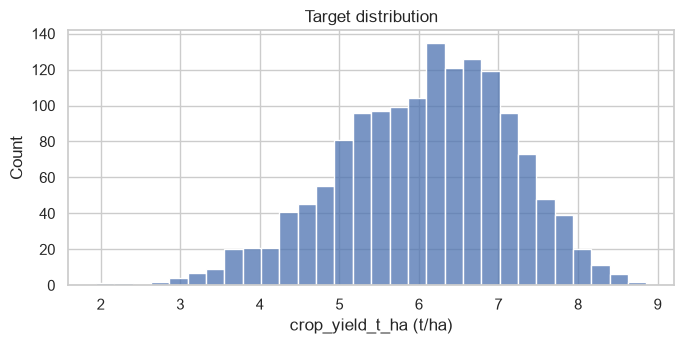

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.histplot(data=df, x=TARGET, bins=30, ax=ax)
ax.set_xlabel("crop_yield_t_ha (t/ha)")
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

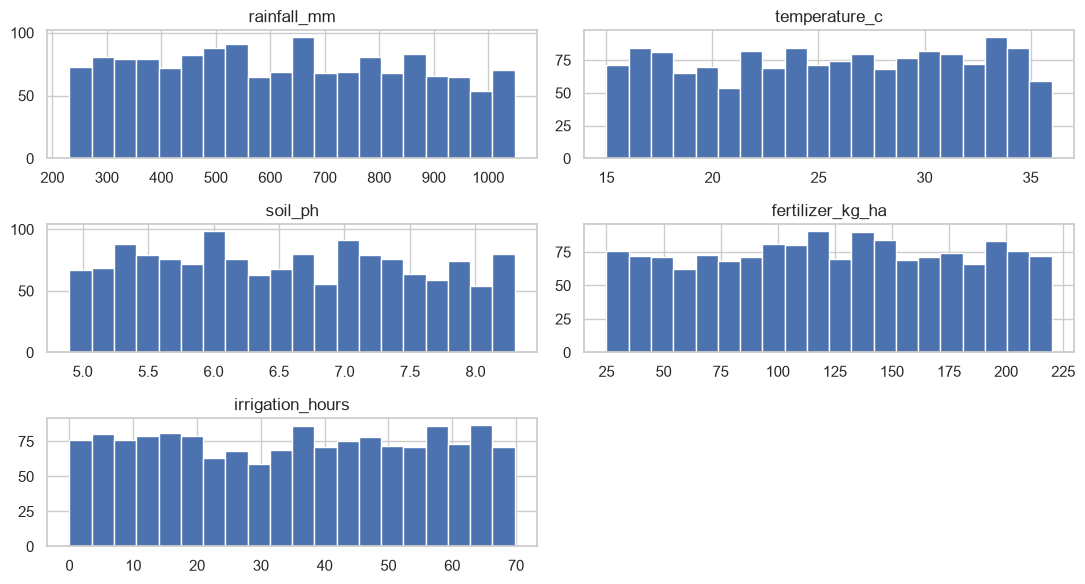

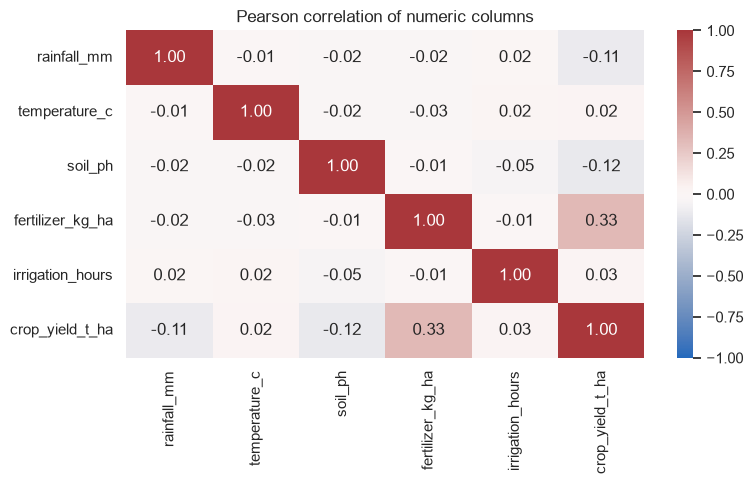

In [5]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC + [TARGET]
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. A seeded random split suits these independently generated rows. The numeric branch fills blanks using training medians. This dataset has no categorical predictors. Tree splits use the ordering of values, so scaling is unnecessary. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [6]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
y = df[TARGET]

### 2. Split the rows into training and test sets

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# Fill blank numbers with the training median.
numeric_preprocess = SimpleImputer(strategy="median")

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`n_estimators` trades compute for stability. `max_depth` and `min_samples_leaf` limit how specific a leaf can be. A fractional `max_features` specifies the share of inputs to consider at each split. Scaling would preserve the order of candidate cutoffs and is unnecessary here.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [9]:
from sklearn.ensemble import RandomForestRegressor

estimator = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=4, max_features=0.8, random_state=SEED, n_jobs=2)
model = Pipeline([
    ("preprocess", preprocess),
    ("model", estimator),
])

### Fit on the training rows

In [10]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['rainfall_mm','temperature_c','soil_ph','fertilizer_kg_ha', 'irrigation_hours']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and w

### Predict on the test rows

In [11]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print(f"Example prediction: {predictions[0]:,.2f} t/ha")

,rainfall_mm,temperature_c,soil_ph,fertilizer_kg_ha,irrigation_hours
1116,500.6,15.4,6.87,204.8,14.0


Example prediction: 6.19 t/ha


## 8. Model Evaluation

Let $y_i$ be the actual test value for row $i$, $\hat y_i$ its prediction, $e_i=y_i-\hat y_i$ its residual, $n$ the number of test rows and $\bar y$ the test target mean.

| Metric | Formula | Interpretation |
| --- | --- | --- |
| Mean absolute error | $\mathrm{MAE}=n^{-1}\sum_i\lvert e_i\rvert$ | Mean absolute miss in the target unit. Lower is better. |
| Mean squared error | $\mathrm{MSE}=n^{-1}\sum_i e_i^2$ | Mean squared miss in squared units. It puts more weight on large errors. Lower is better. |
| Root mean squared error | $\mathrm{RMSE}=\sqrt{\mathrm{MSE}}$ | Error on the target scale that emphasizes large misses. Lower is better. |
| Coefficient of determination | $R^2=1-\sum_i e_i^2/\sum_i(y_i-\bar y)^2$ | Higher is better. One is a perfect fit, zero matches the squared error of the test mean, and negative means more error than that reference. |

The baseline predicts the **training** target mean, so its test R² may be slightly negative. Compare MAE and RMSE to it in the table below.

**Target unit** · t/ha.

In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

initial_metrics = {
    "MAE": mean_absolute_error(y_test, predictions),
    "MSE": mean_squared_error(y_test, predictions),
    "RMSE": root_mean_squared_error(y_test, predictions),
    "R²": r2_score(y_test, predictions),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

MAE     0.515
MSE     0.427
RMSE    0.654
R²      0.635
Name: Test score, dtype: float64

### Compare with a simple baseline

In [13]:
# A baseline predicts the mean training target for every row.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

baseline_metrics = {
    "MAE": mean_absolute_error(y_test, baseline_predictions),
    "MSE": mean_squared_error(y_test, baseline_predictions),
    "RMSE": root_mean_squared_error(y_test, baseline_predictions),
    "R²": r2_score(y_test, baseline_predictions),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,MAE,MSE,RMSE,R²
Baseline,0.855,1.172,1.082,-0.001
Model,0.515,0.427,0.654,0.635


## 9. Visualizations

Compare three trees with the full forest estimate. The forest averages predictions from all fitted trees.

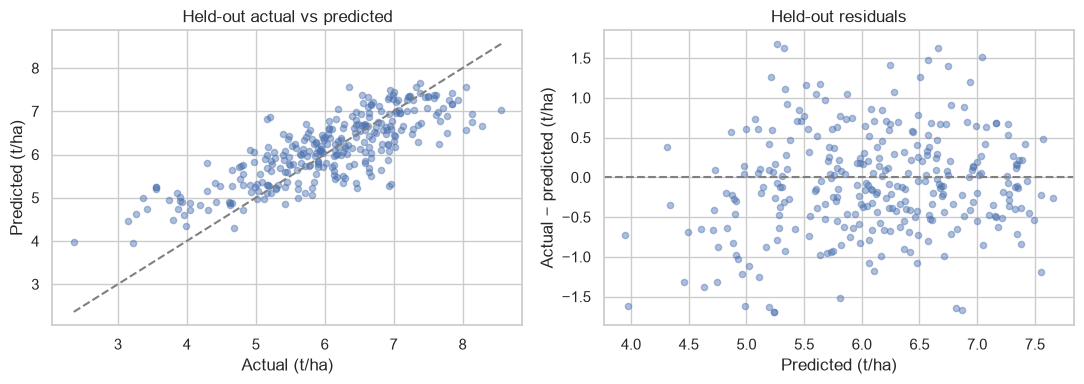

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].scatter(y_test, predictions, s=20, alpha=0.45)
axes[0].plot(limits, limits, color="grey", linestyle="--")
axes[0].set(xlabel="Actual (t/ha)", ylabel="Predicted (t/ha)", title="Held-out actual vs predicted")
axes[1].scatter(predictions, y_test - predictions, s=20, alpha=0.45)
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set(xlabel="Predicted (t/ha)", ylabel="Actual − predicted (t/ha)", title="Held-out residuals")
fig.tight_layout()
plt.show()

### A closer look at this model

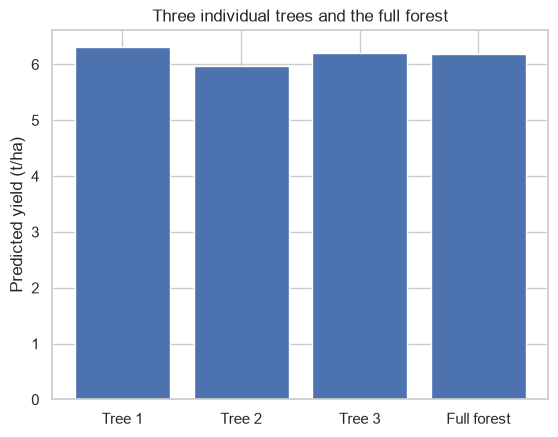

In [15]:
# Ask three fitted trees for their estimates of the same field.
one_field = X_test.head(1)
field_values = model.named_steps["preprocess"].transform(one_field)
trees = model.named_steps["model"].estimators_

tree_1 = trees[0].predict(field_values)[0]
tree_2 = trees[1].predict(field_values)[0]
tree_3 = trees[2].predict(field_values)[0]
forest_yield = model.predict(one_field)[0]

plt.bar(["Tree 1", "Tree 2", "Tree 3", "Full forest"], [tree_1, tree_2, tree_3, forest_yield])
plt.ylabel("Predicted yield (t/ha)")
plt.title("Three individual trees and the full forest")
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by lowest RMSE. The scorer negates RMSE so that the best score ranks first. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`n_estimators` trades compute for stability. `max_depth` and `min_samples_leaf` limit how specific a leaf can be. A fractional `max_features` specifies the share of inputs to consider at each split. Scaling would preserve the order of candidate cutoffs and is unnecessary here.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [16]:
from sklearn.model_selection import GridSearchCV, KFold

param_grid = {"model__n_estimators": [60, 120], "model__max_depth": [6, None], "model__max_features": [0.6, 1.0]}
validation = KFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="neg_root_mean_squared_error", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [17]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean fold RMSE"] = -results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean fold RMSE", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'model__max_depth': None, 'model__max_features': 0.6, 'model__n_estimators': 60}


,rank_test_score,Mean fold RMSE,std_test_score,params
4,1,0.625,0.031,"{'model__max_depth': None, 'model__max_feature..."
7,2,0.625,0.030,"{'model__max_depth': None, 'model__max_feature..."
5,3,0.626,0.031,"{'model__max_depth': None, 'model__max_feature..."
6,4,0.630,0.028,"{'model__max_depth': None, 'model__max_feature..."
3,5,0.667,0.030,"{'model__max_depth': 6, 'model__max_features':..."


### Compare the models on the test set

In [18]:
tuned_predictions = tuned_model.predict(X_test)

tuned_metrics = {
    "MAE": mean_absolute_error(y_test, tuned_predictions),
    "MSE": mean_squared_error(y_test, tuned_predictions),
    "RMSE": root_mean_squared_error(y_test, tuned_predictions),
    "R²": r2_score(y_test, tuned_predictions),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,MAE,MSE,RMSE,R²
Baseline,0.855,1.172,1.082,-0.001
First model,0.515,0.427,0.654,0.635
Tuned model,0.516,0.423,0.651,0.638


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. Read the estimates in t/ha and compare the scenarios to see how the fitted model responds.

### Enter three new examples

In [19]:
examples = pd.DataFrame([
    [610, 25, 6.6, 130, 29],
    [305, 33, 5.7, 85, 12],
    [940, 20, 7.2, 165, 36],
], columns=FEATURES)
display(examples)

,rainfall_mm,temperature_c,soil_ph,fertilizer_kg_ha,irrigation_hours
0,610,25,6.6,130,29
1,305,33,5.7,85,12
2,940,20,7.2,165,36


### Make predictions

In [20]:
sample_inputs = examples
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Near the water and temperature optima","Warm season with low rainfall","Cool, wet season"]
example_output["Predicted crop_yield_t_ha (t/ha)"] = sample_predictions.round(2)
display(example_output)

,rainfall_mm,temperature_c,soil_ph,fertilizer_kg_ha,irrigation_hours,Scenario,Predicted crop_yield_t_ha (t/ha)
0,610,25,6.6,130,29,Near the water and temperature optima,7.47
1,305,33,5.7,85,12,Warm season with low rainfall,5.04
2,940,20,7.2,165,36,"Cool, wet season",6.32


## 12. Limitations and Advantages

Forests capture broad nonlinear patterns and interactions with modest setup. Because predictions average training targets, extrapolation to unprecedented droughts is weak. Very small leaves can fit noise, and shallow trees can miss optima. Predictions also require more work than one tree. Use for interpolation in representative tabular data. Consider a structural model for extrapolation or dependence across seasons and sites.

## 13. Interview Preparation

### A. 30-second explanation

> I fitted a random forest to synthetic crop yields driven by water, temperature, pH and fertilizer. Each tree partitions a bootstrap sample and estimates a leaf mean. Averaging the means reduced sensitivity to single-tree cutoffs. I evaluated error in tonnes per hectare and examined which features drove the tree splits.

### B. 90-second technical explanation

> I fitted a random forest to synthetic crop yields driven by water, temperature, pH and fertilizer. Each tree partitions a bootstrap sample and estimates a leaf mean. Averaging the means reduced sensitivity to single-tree cutoffs. I evaluated error in tonnes per hectare and examined which features drove the tree splits. My target was crop yield t ha, and the inputs were rainfall mm, temperature c, soil ph, fertilizer kg ha, irrigation hours. Sample training fields with replacement, grow regression trees with randomized candidate features, then route a new field through every tree. Average the leaf means. Different tree structures smooth the jumps of an individual tree, while the ensemble remains a collection of piecewise constants. I held out 20% of the rows and fitted preprocessing within each training fold. I measured MAE in t/ha and RMSE to see how much larger errors mattered. I compared the model with a training-mean predictor and inspected residuals. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **What is averaged?** Continuous predictions from all trees.
2. **Why randomize features?** To increase diversity and reduce correlation among trees.
3. **What does a squared-error leaf return?** The target mean for the observations in that leaf.
4. **Can predictions exceed the training range?** An average of standard leaf means stays within the training target range.
5. **What does min_samples_leaf change?** The granularity and stability of the leaf estimates.
6. **What does adding more trees do?** It reduces Monte Carlo variability with diminishing returns.
7. **How do you interpret RMSE in this project?** It measures error on the original yield scale and emphasizes large misses.
8. **Why might rainfall and irrigation have related importance?** Both carry information about water, including interactions.
9. **What is an out-of-bag prediction?** An average over the trees that omitted that training row.
10. **Do spread across trees and prediction interval mean the same thing?** No. Tree spread does not by itself capture conditional outcome noise.

### D. Five scenario questions

1. **A new region has much lower rainfall. What would you do?** Validate with measurements from that region before relying on forest interpolation.
2. **Repeated rows come from the same farms. How should you split?** Group rows by farm so a holdout tests transfer to unseen farms.
3. **The forest misses high yields. What would you inspect?** Examine residuals by target range and the sizes and means of reached leaves.
4. **A single importance ranking changes across seeds. What would you inspect?** Check correlated predictors and repeated permutation importance.
5. **The model’s rainfall relationship differs by irrigation. How can you visualize it?** Plot representative conditional profiles for several irrigation levels within observed support.

### E. Three common mistakes

- Treating a tree-average as a prediction interval. Use a validated uncertainty method.
- Assuming more trees fix systematic bias. Inspect residual patterns and leaf size.
- Using standard scaling solely because units differ. Trees split by ordering.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [21]:
from IPython.display import Markdown

summary = (
    "I built a supervised regression project for agriculture crop yield prediction using Random Forest Regressor. I generated 1,500 synthetic observations and used rainfall mm, temperature c, soil ph, fertilizer kg ha, irrigation hours to predict crop yield t ha. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model achieved MAE {tuned_metrics['MAE']:,.2f} t/ha, "
    f"compared with {baseline_metrics['MAE']:,.2f} t/ha for the training-mean baseline. "
    f"Its RMSE was {tuned_metrics['RMSE']:,.2f} t/ha. "
    "I compared three individual tree predictions with the full forest estimate for one field. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised regression project for agriculture crop yield prediction using Random Forest Regressor. I generated 1,500 synthetic observations and used rainfall mm, temperature c, soil ph, fertilizer kg ha, irrigation hours to predict crop yield t ha. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model achieved MAE 0.52 t/ha, compared with 0.85 t/ha for the training-mean baseline. Its RMSE was 0.65 t/ha. I compared three individual tree predictions with the full forest estimate for one field. These results apply to the synthetic data and should be validated on representative observations before practical use.